# What Do Investor Holdings Reveal About Firms?
## An end-to-end replication of *Asset Embeddings*

This notebook tells the complete replication story of Gabaix, Koijen, Richmond, and Yogo, *Asset Embeddings* (BFI Working Paper 2025-51). Rather than presenting disconnected model scores, it follows the sequence of questions that guided the project: **Can holdings recover economically meaningful firm representations? Do those representations explain valuation and return comovement? Can they predict what investors hold?**

The short answer is **yes, with important differences across tasks**. Recommender-system embeddings are strongest for relative valuation, holdings add information beyond conventional characteristics for return comovement, and Word2Vec is particularly strong when predicting masked portfolio positions.

This is a read-only results notebook. It performs no downloads and fits no models. Every table and figure is reconstructed from checkpointed artifacts produced by `Full_Replication_80Q.ipynb`, `Robustness_and_Sanity_Checks.ipynb`, and `Remaining_Benchmarks.ipynb`.

## 1. Starting question and final answer

The paper treats the holdings matrix as a revealed-preference map between investors and firms. If investors group economically similar firms in similar portfolios, a low-dimensional model should recover firm attributes that are useful outside the holdings matrix itself.

We therefore required success on three progressively different tests:

1. **Relative valuation:** do embeddings explain why otherwise similar firms trade at different valuations?
2. **Return comovement:** do lagged embeddings explain which firms move together next quarter?
3. **Managed portfolios:** can the model infer a deliberately hidden holding from the rest of an investor's portfolio?

Passing all three would show that the embeddings capture more than mechanical reconstruction of the input matrix.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

PROJECT_ROOT=Path.cwd().resolve()
if PROJECT_ROOT.name!='Asset_Embeddings':
    candidate=PROJECT_ROOT/'Projects'/'Asset_Embeddings'
    if candidate.exists(): PROJECT_ROOT=candidate.resolve()
if PROJECT_ROOT.name!='Asset_Embeddings':
    raise RuntimeError('Open this notebook from the Asset_Embeddings project directory.')
os.chdir(PROJECT_ROOT)
FULL_ROOT=PROJECT_ROOT/'full_replication_80q'
REMAINING_ROOT=PROJECT_ROOT/'remaining_benchmarks'
SUMMARY_ROOT=PROJECT_ROOT/'replication_summary'
FIGURE_ROOT=SUMMARY_ROOT/'figures'; FIGURE_ROOT.mkdir(parents=True,exist_ok=True)

COLORS={'control':'#A7A9AC','beta':'#6D6E71','characteristics':'#40464F','rs4':'#9DB9D3','rs10':'#356A9A','word2vec4':'#DDA09A','word2vec10':'#A94442','combined':'#173F5F'}
MODEL_LABELS={'placebo':'Placebo','beta':'Beta','characteristics':'Characteristics','rs_binary':'RS-Binary','rs_ranks':'RS-Ranks','rs_l_0':'RS-L-0','rs_l_min':'RS-L-Min','rs_l':'RS-L','word2vec':'Word2Vec'}
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':220,'font.size':10,'axes.titlesize':12,'axes.labelsize':10,'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#333333','axes.linewidth':0.8,'axes.grid':True,'grid.alpha':0.20,'axes.axisbelow':True,'xtick.color':'#333333','ytick.color':'#333333'})

def add_labels(ax,bars,decimals=1):
    for bar in bars:
        value=bar.get_height(); offset=max(abs(ax.get_ylim()[1]-ax.get_ylim()[0])*.012,.15)
        ax.text(bar.get_x()+bar.get_width()/2,value+(offset if value>=0 else -offset),f'{value:.{decimals}f}',ha='center',va='bottom' if value>=0 else 'top',fontsize=8,fontweight='semibold')

def finish_figure(fig,name):
    fig.tight_layout(); fig.savefig(FIGURE_ROOT/f'{name}.png',bbox_inches='tight'); fig.savefig(FIGURE_ROOT/f'{name}.pdf',bbox_inches='tight'); plt.show()

required=[FULL_ROOT/'robustness/targets/training_only_target_summary.parquet',REMAINING_ROOT/'return_comovement/summary.parquet',REMAINING_ROOT/'managed_portfolio/managed_portfolio_summary.parquet',REMAINING_ROOT/'replication_benchmark_completion.parquet']
artifact_audit=pd.DataFrame({'artifact':[str(p.relative_to(PROJECT_ROOT)) for p in required],'exists':[p.exists() for p in required]})
display(artifact_audit); assert artifact_audit.exists.all()

Matplotlib is building the font cache; this may take a moment.


,artifact,exists
0,full_replication_80q/robustness/targets/traini...,True
1,remaining_benchmarks/return_comovement/summary...,True
2,remaining_benchmarks/managed_portfolio/managed...,True
3,remaining_benchmarks/replication_benchmark_com...,True


## 2. Building the empirical system

The replication uses quarterly institutional holdings from 2005Q1 through 2024Q4. S12 mutual-fund portfolios are linked to non-overlapping S34 institutional managers and then mapped to CRSP firms at the PERMCO level. The investable universe retains ordinary common shares, removes very small firms, eliminates highly concentrated investors, and iteratively requires at least 20 firms per investor and 20 investors per firm.

Six holdings-based representations are compared: RS-Binary, RS-Ranks, RS-L-0, RS-L-Min, RS-L, and Word2Vec. The recommender systems compress different transformations of the investor–firm matrix; Word2Vec instead learns which firms repeatedly occur in the same portfolios. The main dimensions are 4 and 10. The paper uses a six-dimensional base model for its return and managed-portfolio benchmarks; our four-dimensional base is therefore a documented deviation, while the ten-dimensional comparison is directly aligned.

This construction gave us a common quarterly firm universe and a consistent set of embeddings. The next question was whether those coordinates contained economically meaningful information rather than merely reconstructing holdings.

In [2]:
matrix_files=sorted((FULL_ROOT/'matrices').glob('*/matrix_summary.parquet'))
matrix_inventory=pd.concat([pd.read_parquet(p).assign(quarter_label=p.parent.name) for p in matrix_files],ignore_index=True)
summary_table=pd.DataFrame({
    'Statistic':['Sample period','Quarters','Mean investors per quarter','Mean firms per quarter','Mean nonzero holdings per quarter','Embedding models','Primary dimensions'],
    'Replication':['2005Q1–2024Q4',len(matrix_files),f"{matrix_inventory.investors.mean():,.0f}",f"{matrix_inventory.firms.mean():,.0f}",f"{matrix_inventory.nonzero_entries.mean():,.0f}" if 'nonzero_entries' in matrix_inventory else 'See matrix inventory','6','4 and 10']
})
display(summary_table)

,Statistic,Replication
0,Sample period,2005Q1–2024Q4
1,Quarters,80
2,Mean investors per quarter,"7,480"
3,Mean firms per quarter,"1,578"
4,Mean nonzero holdings per quarter,See matrix inventory
5,Embedding models,6
6,Primary dimensions,4 and 10


## 3. First test: explaining relative valuation

Following the paper, relative valuation is the quarterly residual from regressing log market equity on log book equity. Book equity is used only to construct the target and is excluded from every downstream predictor set. Firms are divided 80%/20% into training and test samples, predictors are standardized on training firms, and ridge penalties are selected by ten-fold cross-validation. The figure reports mean out-of-sample variance R² across 80 quarters using the stricter training-only reconstruction of the valuation target.

This is the natural first test because a successful result would show that portfolio neighborhoods encode information about how the market values firms relative to fundamentals.

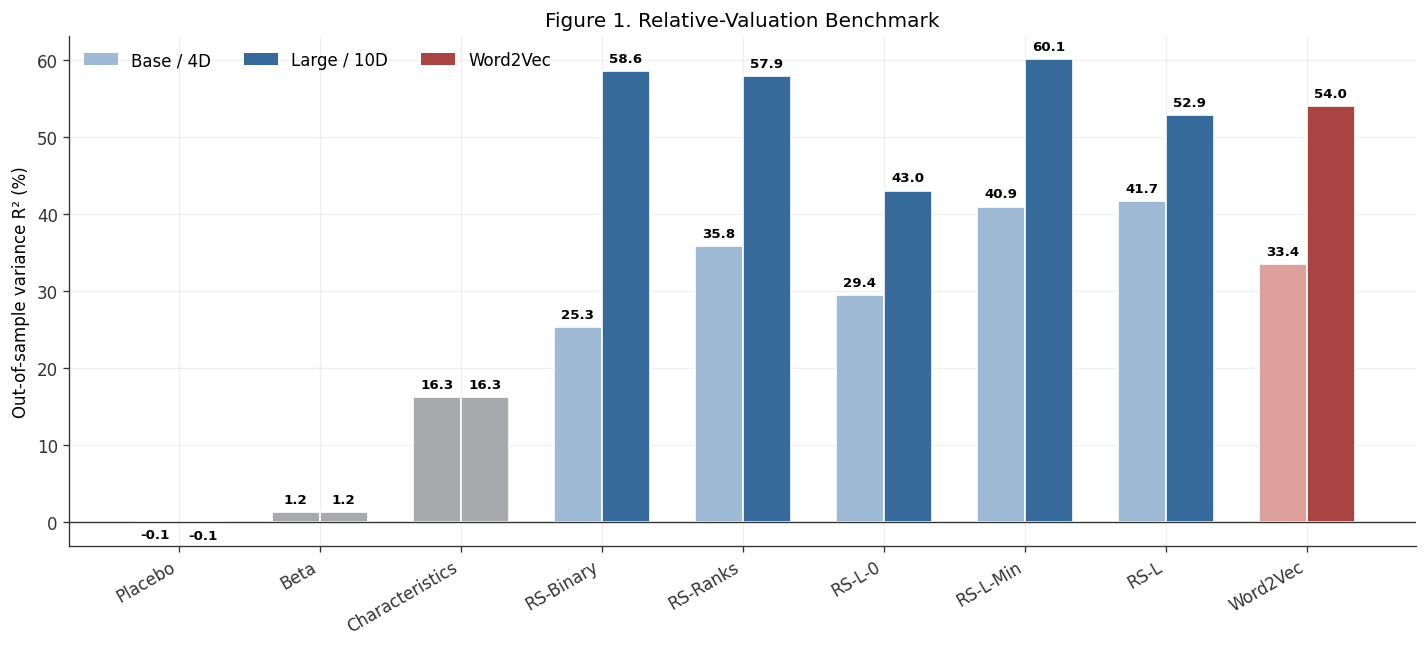

,model,mean,std,min,max
0,rs_l_min_10,0.600798,0.090452,0.404959,0.801000
1,rs_binary_10,0.585670,0.079030,0.385865,0.735596
2,rs_ranks_10,0.578874,0.076053,0.432519,0.726012
3,word2vec_10,0.539885,0.068134,0.381338,0.711471
4,rs_l_10,0.528573,0.102186,0.307058,0.749541
5,rs_l_0_10,0.430113,0.087666,0.256368,0.664437
6,rs_l_4,0.417070,0.107244,0.202544,0.704098
7,rs_l_min_4,0.409320,0.093193,0.197509,0.630600
8,rs_ranks_4,0.358103,0.086662,0.073695,0.581917
9,word2vec_4,0.334398,0.091316,0.149432,0.594333


In [3]:
rv=pd.read_parquet(FULL_ROOT/'robustness/targets/training_only_target_summary.parquet')
rv_controls=pd.read_parquet(FULL_ROOT/'additional_recommender_systems/benchmarks/complete_rs_valuation_summary.parquet').rename(columns={'mean_test_variance_r2':'mean','standard_deviation_test_r2':'std','minimum_test_variance_r2':'min','maximum_test_variance_r2':'max'})
rv=pd.concat([rv,rv_controls[~rv_controls.model.isin(rv.model)][rv.columns]],ignore_index=True)
rv_lookup=rv.set_index('model')['mean']
models=['placebo','beta','characteristics','rs_binary','rs_ranks','rs_l_0','rs_l_min','rs_l','word2vec']
rv_rows=[]
for model in models:
    for dimension in [4,10]:
        key={'placebo':f'placebo_{dimension}','beta':'beta','characteristics':'characteristics_4'}.get(model,f'{model}_{dimension}')
        if key in rv_lookup: rv_rows.append({'model':model,'dimension':dimension,'r2':100*rv_lookup[key]})
rv_plot=pd.DataFrame(rv_rows)
x=np.arange(len(models)); width=.34; fig,ax=plt.subplots(figsize=(12,5.5))
v4=[rv_plot.query('model==@m and dimension==4').r2.iloc[0] if len(rv_plot.query('model==@m and dimension==4')) else np.nan for m in models]
v10=[rv_plot.query('model==@m and dimension==10').r2.iloc[0] if len(rv_plot.query('model==@m and dimension==10')) else np.nan for m in models]
b4=ax.bar(x-width/2,np.nan_to_num(v4,nan=0),width,label='Base / 4D',color=[COLORS['control'] if m in ['placebo','beta','characteristics'] else COLORS['word2vec4'] if m=='word2vec' else COLORS['rs4'] for m in models],edgecolor='white')
b10=ax.bar(x+width/2,np.nan_to_num(v10,nan=0),width,label='Large / 10D',color=[COLORS['control'] if m in ['placebo','beta','characteristics'] else COLORS['word2vec10'] if m=='word2vec' else COLORS['rs10'] for m in models],edgecolor='white')
add_labels(ax,b4); add_labels(ax,b10); ax.set_xticks(x, [MODEL_LABELS[m] for m in models],rotation=30,ha='right'); ax.set_ylabel('Out-of-sample variance R² (%)'); ax.set_title('Figure 1. Relative-Valuation Benchmark'); ax.axhline(0,color='#333333',linewidth=.8); ax.legend(handles=[Patch(facecolor=COLORS['rs4'],label='Base / 4D'),Patch(facecolor=COLORS['rs10'],label='Large / 10D'),Patch(facecolor=COLORS['word2vec10'],label='Word2Vec')],frameon=False,ncol=3); finish_figure(fig,'figure_1_relative_valuation')
display(rv.sort_values('mean',ascending=False).reset_index(drop=True))

### What the first result established

RS-L-Min is the strongest ten-dimensional model, explaining approximately **60.1%** of relative valuation out of sample. RS-Binary and RS-Ranks follow at **58.6%** and **57.9%**. Word2Vec explains approximately **54.0%**, while four observed firm characteristics explain only **16.3%**. The placebo has essentially zero explanatory power.

The large gap relative to characteristics established that holdings contain meaningful valuation information. But valuation is a contemporaneous cross-sectional target. We therefore moved to a harder temporal question: whether quarter `t−1` embeddings explain return comovement in quarter `t`.

## 4. Second test: predicting return comovement

Quarter `t−1` embeddings explain monthly returns in quarter `t`. Each monthly cross-section uses the same 80%/20% firm split across models, training-only standardization, and ten-fold ridge selection. The performance measure is Equation (14), averaged over 237 months and 79 quarter transitions.

Lagging the embeddings matters: this test asks whether the learned firm representation travels forward in time rather than simply fitting contemporaneous outcomes.

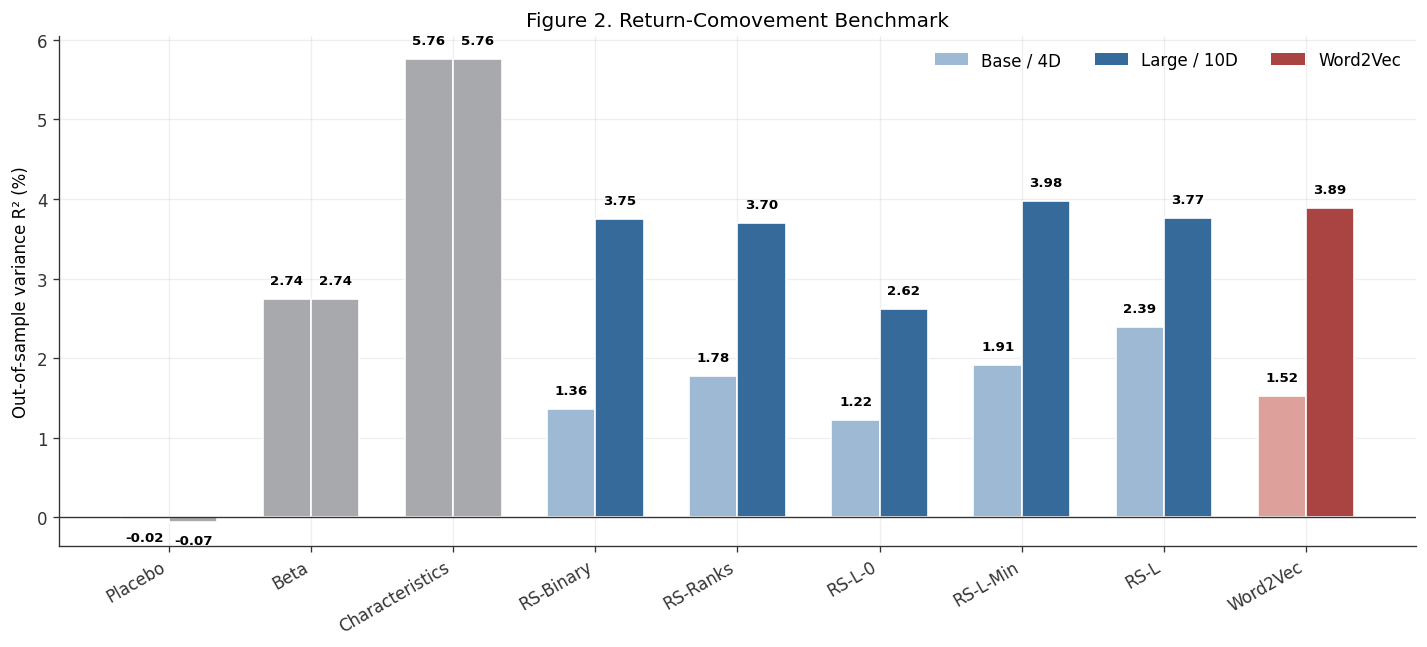

,model,return_comovement_r2,monthly_r2_std,months,mean_selected_alpha
0,rs_l_min_10_plus_characteristics,0.069985,0.066864,237,456.688986
1,rs_binary_10_plus_characteristics,0.068794,0.064544,237,447.641442
2,rs_l_10_plus_characteristics,0.068138,0.063666,237,486.141531
3,rs_ranks_10_plus_characteristics,0.067959,0.062615,237,410.967806
4,word2vec_10_plus_characteristics,0.066959,0.065712,237,4882.206013
5,rs_l_0_10_plus_characteristics,0.064292,0.061990,237,474.897846
6,characteristics_6,0.057584,0.061023,237,4667.411610
7,rs_l_min_10,0.039758,0.040783,237,423.404159
8,word2vec_10,0.038928,0.042881,237,4796.663005
9,rs_l_10,0.037651,0.039183,237,4713.057310


In [4]:
rc=pd.read_parquet(REMAINING_ROOT/'return_comovement/summary.parquet')
rc_lookup=rc.set_index('model')['return_comovement_r2']
rc_models=['placebo','beta','characteristics','rs_binary','rs_ranks','rs_l_0','rs_l_min','rs_l','word2vec']
r4=[]; r10=[]
for m in rc_models:
    r4.append(100*rc_lookup.get({'placebo':'placebo_4','beta':'beta','characteristics':'characteristics_6'}.get(m,f'{m}_4'),np.nan))
    r10.append(100*rc_lookup.get({'placebo':'placebo_10','beta':'beta','characteristics':'characteristics_6'}.get(m,f'{m}_10'),np.nan))
x=np.arange(len(rc_models)); width=.34; fig,ax=plt.subplots(figsize=(12,5.5))
b4=ax.bar(x-width/2,r4,width,label='Base / 4D',color=[COLORS['control'] if m in ['placebo','beta','characteristics'] else COLORS['word2vec4'] if m=='word2vec' else COLORS['rs4'] for m in rc_models],edgecolor='white')
b10=ax.bar(x+width/2,r10,width,label='Large / 10D',color=[COLORS['control'] if m in ['placebo','beta','characteristics'] else COLORS['word2vec10'] if m=='word2vec' else COLORS['rs10'] for m in rc_models],edgecolor='white')
add_labels(ax,b4,2); add_labels(ax,b10,2); ax.set_xticks(x,[MODEL_LABELS[m] for m in rc_models],rotation=30,ha='right'); ax.set_ylabel('Out-of-sample variance R² (%)'); ax.set_title('Figure 2. Return-Comovement Benchmark'); ax.axhline(0,color='#333333',linewidth=.8); ax.legend(handles=[Patch(facecolor=COLORS['rs4'],label='Base / 4D'),Patch(facecolor=COLORS['rs10'],label='Large / 10D'),Patch(facecolor=COLORS['word2vec10'],label='Word2Vec')],frameon=False,ncol=3); finish_figure(fig,'figure_2_return_comovement')
display(rc.sort_values('return_comovement_r2',ascending=False).reset_index(drop=True))

### Why the return result led to a combined model

Six characteristics explain **5.76%** of monthly return comovement, close to the paper's 5.3%, while beta explains **2.74%**, close to the paper's approximately 2%. RS-L-Min is the strongest standalone ten-dimensional embedding at **3.98%**. Thus, as in the paper, holdings embeddings outperform beta but do not surpass the carefully selected six-characteristic benchmark alone.

That result does not imply that embeddings are redundant. The correct next test is incremental: if embeddings and characteristics capture different information, combining them should improve on characteristics alone.

## 5. Third step: testing incremental information

We now plot each ten-dimensional embedding alone and combined with the six-characteristic vector. This comparison distinguishes substitution from complementarity: an embedding can be weaker alone yet still contribute information that characteristics miss.

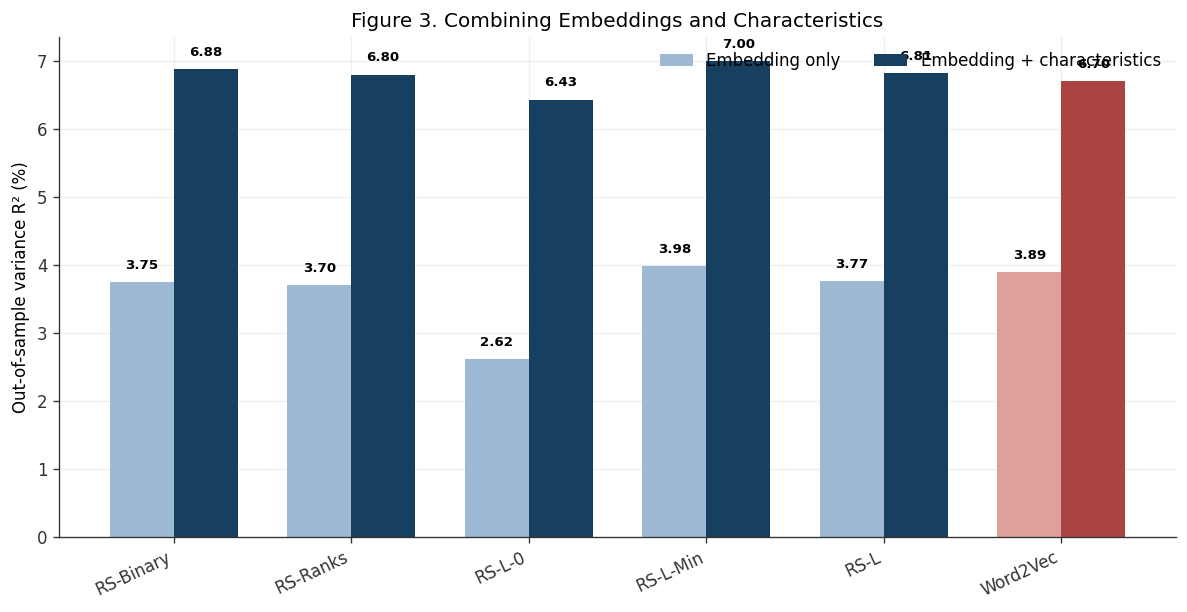

In [5]:
combine_models=['rs_binary','rs_ranks','rs_l_0','rs_l_min','rs_l','word2vec']
standalone=[100*rc_lookup[f'{m}_10'] for m in combine_models]
combined=[100*rc_lookup[f'{m}_10_plus_characteristics'] for m in combine_models]
x=np.arange(len(combine_models)); width=.36; fig,ax=plt.subplots(figsize=(10,5.2))
b1=ax.bar(x-width/2,standalone,width,label='Embedding only',color=[COLORS['word2vec4'] if m=='word2vec' else COLORS['rs4'] for m in combine_models])
b2=ax.bar(x+width/2,combined,width,label='Embedding + characteristics',color=[COLORS['word2vec10'] if m=='word2vec' else COLORS['combined'] for m in combine_models])
add_labels(ax,b1,2); add_labels(ax,b2,2); ax.set_xticks(x,[MODEL_LABELS[m] for m in combine_models],rotation=25,ha='right'); ax.set_ylabel('Out-of-sample variance R² (%)'); ax.set_title('Figure 3. Combining Embeddings and Characteristics'); ax.legend(frameon=False,ncol=2); finish_figure(fig,'figure_3_embeddings_plus_characteristics')

### What the combined models revealed

Every embedding improves on characteristics when the two information sets are combined. RS-L-Min plus characteristics reaches **7.00%**, followed by RS-Binary at **6.88%**. The consistent gains show that holdings recover information not summarized by standard accounting and market variables.

At this point, the embeddings had passed both valuation and return tests. The final benchmark changed perspective from firms to investors: could a representation infer a missing asset from the surrounding portfolio?

## 6. Final economic test: reconstructing a managed portfolio

The managed-portfolio experiment follows the paper's single-cross-section design. Models are fitted on 90% of investors in 2024Q4. For each held-out investor, the second-largest position is masked and predicted from the remaining portfolio. Scores measure log likelihood relative to random guessing, with an upper bound of one.

This is not another valuation regression. It directly tests whether the learned geometry recognizes which assets belong together inside actual portfolios.

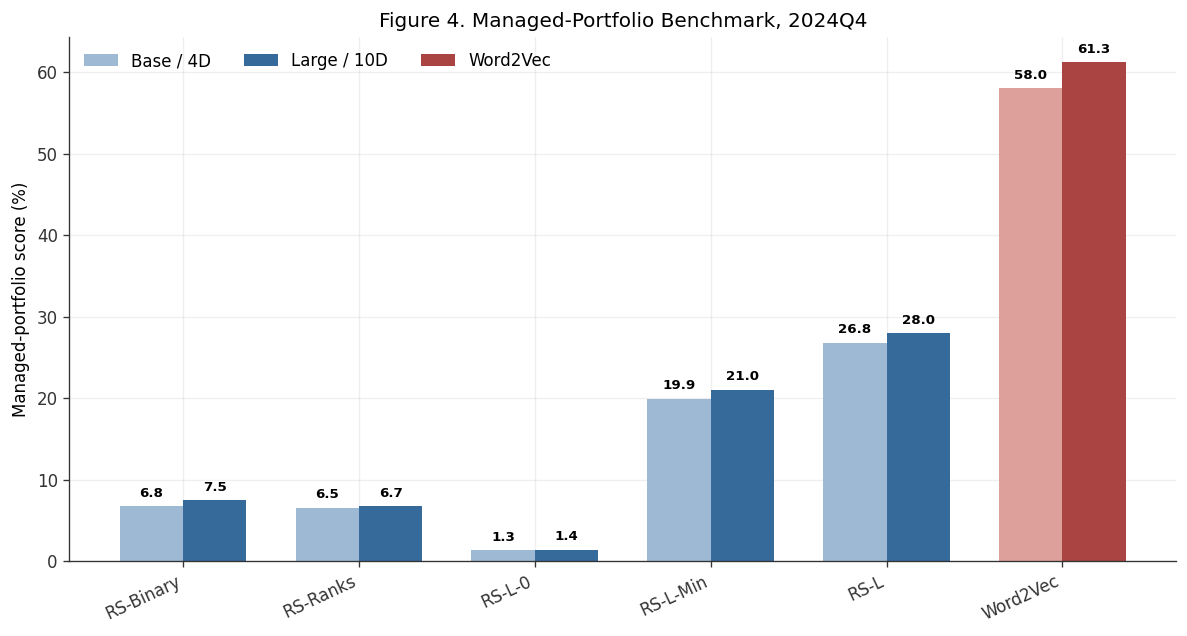

,model,dimension,test_investors,mean_log_probability,mean_random_log_probability,top_1_accuracy,top_10_accuracy,median_rank,managed_portfolio_score
0,word2vec,10,1183,-2.824185,-7.295605,0.515638,0.644970,1.0,0.612892
1,word2vec,4,1183,-3.060550,-7.295605,0.502113,0.628910,1.0,0.580494
2,rs_l,10,1183,-5.255679,-7.295605,0.480135,0.648352,2.0,0.279610
3,rs_l,4,1183,-5.339856,-7.295605,0.489434,0.640744,2.0,0.268072
4,rs_l_min,10,1183,-5.760162,-7.295605,0.555368,0.729501,1.0,0.210461
5,rs_l_min,4,1183,-5.840338,-7.295605,0.544379,0.699070,1.0,0.199472
6,rs_binary,10,1183,-6.751994,-7.295605,0.480981,0.686391,2.0,0.074512
7,rs_binary,4,1183,-6.802708,-7.295605,0.499577,0.661877,2.0,0.067561
8,rs_ranks,10,1183,-6.804717,-7.295605,0.562975,0.745562,1.0,0.067285
9,rs_ranks,4,1183,-6.818853,-7.295605,0.551986,0.710059,1.0,0.065348


In [6]:
mp=pd.read_parquet(REMAINING_ROOT/'managed_portfolio/managed_portfolio_summary.parquet')
mp_models=['rs_binary','rs_ranks','rs_l_0','rs_l_min','rs_l','word2vec']; lookup=mp.set_index(['model','dimension'])['managed_portfolio_score']
m4=[100*lookup.loc[(m,4)] for m in mp_models]; m10=[100*lookup.loc[(m,10)] for m in mp_models]
x=np.arange(len(mp_models)); width=.36; fig,ax=plt.subplots(figsize=(10,5.4))
b4=ax.bar(x-width/2,m4,width,label='Base / 4D',color=[COLORS['word2vec4'] if m=='word2vec' else COLORS['rs4'] for m in mp_models])
b10=ax.bar(x+width/2,m10,width,label='Large / 10D',color=[COLORS['word2vec10'] if m=='word2vec' else COLORS['rs10'] for m in mp_models])
add_labels(ax,b4); add_labels(ax,b10); ax.set_xticks(x,[MODEL_LABELS[m] for m in mp_models],rotation=25,ha='right'); ax.set_ylabel('Managed-portfolio score (%)'); ax.set_title('Figure 4. Managed-Portfolio Benchmark, 2024Q4'); ax.legend(handles=[Patch(facecolor=COLORS['rs4'],label='Base / 4D'),Patch(facecolor=COLORS['rs10'],label='Large / 10D'),Patch(facecolor=COLORS['word2vec10'],label='Word2Vec')],frameon=False,ncol=3); finish_figure(fig,'figure_4_managed_portfolio')
display(mp)

### Why the winning model changed

Word2Vec performs best, scoring **61.3%** at ten dimensions, followed by RS-L at **28.0%** and RS-L-Min at **21.0%**. The ordering agrees qualitatively with the paper. Word2Vec's local co-occurrence objective closely matches a masked-holding task, whereas the global recommender systems were better suited to explaining cross-sectional valuation.

The Word2Vec magnitude exceeds the paper's approximately 29% result, but this is not an exact numerical comparison: our experiment uses the combined S12–S34 universe in 2024Q4 rather than the paper's managed-portfolio sample in 2022Q4. The broader lesson is therefore about model specialization, not a claim that our estimate dominates the paper's.

## 7. Could the headline results be artificial?

Because the valuation R² is large, we treated leakage and implementation integrity as substantive empirical questions. We verified complete embedding availability, finite values, full evaluation-firm coverage, fresh quarterly reconstruction of the valuation target, alternative train/test seeds, a stricter inductive PCA fold-in experiment, and the RS-L regularization choices.

In [7]:
integrity=pd.read_parquet(FULL_ROOT/'robustness/audits/embedding_integrity.parquet')
target=pd.read_parquet(FULL_ROOT/'robustness/targets/target_audit.parquet')
seeds=pd.read_parquet(FULL_ROOT/'robustness/splits/five_seed_summary.parquet')
robustness=pd.DataFrame({
 'Check':['Embedding availability','Finite embeddings','Evaluation-firm coverage','Valuation-target reconstruction','Alternative firm splits','Strict inductive PCA fold-in','RS-L regularization selection'],
 'Result':['960/960 files present','960/960 passed','100% in every file',f"Maximum error = {target.maximum_rebuild_error.max():.1f}",'Principal rankings stable across five seeds','Positive R² in all three pilot quarters','Regularization 10 won all 160 cases'],
 'Conclusion':['Pass','Pass','Pass','Pass','Pass','Pass','Pass']})
display(robustness); display(seeds.pivot(index='model',columns='seed',values='r2'))

,Check,Result,Conclusion
0,Embedding availability,960/960 files present,Pass
1,Finite embeddings,960/960 passed,Pass
2,Evaluation-firm coverage,100% in every file,Pass
3,Valuation-target reconstruction,Maximum error = 0.0,Pass
4,Alternative firm splits,Principal rankings stable across five seeds,Pass
5,Strict inductive PCA fold-in,Positive R² in all three pilot quarters,Pass
6,RS-L regularization selection,Regularization 10 won all 160 cases,Pass


seed,202451,202452,202453,202454,202455
model,,,,,
characteristics_4,0.162542,0.165420,0.161545,0.155341,0.166377
rs_binary_10,0.585670,0.592492,0.597594,0.594960,0.587456
rs_l_min_10,0.600798,0.601931,0.610759,0.607627,0.601758
word2vec_10,0.539885,0.547130,0.546876,0.544201,0.536439


## 8. What replicated—and what did not match exactly

The replication matches the paper's central qualitative findings across all three benchmarks. Holdings embeddings strongly explain relative valuation; conventional characteristics remain a high hurdle for return comovement; embeddings add information when combined with characteristics; and Word2Vec is especially effective for masked managed-portfolio prediction.

The replication is close rather than literal. The following differences define the boundary of the comparison and should accompany every presentation of the results:

1. The replication combines S12 mutual funds with non-overlapping S34 institutions rather than using the paper's proprietary managed-portfolio sample.
2. The sample extends through 2024Q4 rather than ending in 2022Q4.
3. The managed-portfolio test uses 2024Q4; the paper reports 2022Q4.
4. The base embedding dimension is four rather than six in the return-comovement and managed-portfolio displays. Ten-dimensional comparisons are aligned.
5. BERT, OpenAI text embeddings, and Cohere text embeddings are not replicated because the underlying inputs and historical APIs are unavailable.
6. RS-L 4D reached its 50-iteration cap with a very small final RMSE improvement; the main 10D model converged after 32 iterations.

## 9. Final conclusion

The evidence accumulated in a clear sequence:

1. Holdings embeddings explained a large share of out-of-sample relative valuation, far above observed characteristics.
2. Lagged embeddings explained next-quarter return comovement better than beta, although six firm characteristics remained the strongest standalone benchmark.
3. Combining embeddings with characteristics improved on characteristics alone, demonstrating genuinely incremental information.
4. Word2Vec excelled at recovering a masked portfolio position, showing that local co-holding structure is especially useful for investor-choice prediction.
5. Leakage, split-sensitivity, and implementation audits did not overturn the central rankings.

Taken together, the replication supports the paper's main economic claim: **the cross-section of investor holdings contains a rich representation of firms that is not reducible to standard accounting characteristics.** It also adds an important practical qualification—there is no universally best embedding. Global recommender systems, especially RS-L-Min, are strongest for relative valuation; Word2Vec is best aligned with masked portfolio prediction; and characteristics plus embeddings provide the strongest return-comovement specification.

These completed and audited artifacts became the frozen baseline for the active-versus-passive extension, where the next question was not whether holdings embeddings work, but **which investors make them most informative**.

## 10. Limitations and reproducibility

The tables below map every headline result back to its generating notebook and immutable local artifact. Running this summary requires neither WRDS nor model refitting; it only redraws the final evidence.

In [8]:
manifest=pd.DataFrame([
 {'Result':'Relative valuation','Source notebook':'Full_Replication_80Q.ipynb + Robustness_and_Sanity_Checks.ipynb','Artifact':'full_replication_80q/robustness/targets/training_only_target_summary.parquet'},
 {'Result':'Return comovement','Source notebook':'Remaining_Benchmarks.ipynb','Artifact':'remaining_benchmarks/return_comovement/summary.parquet'},
 {'Result':'Managed portfolios','Source notebook':'Remaining_Benchmarks.ipynb','Artifact':'remaining_benchmarks/managed_portfolio/managed_portfolio_summary.parquet'},
 {'Result':'Embedding integrity','Source notebook':'Robustness_and_Sanity_Checks.ipynb','Artifact':'full_replication_80q/robustness/audits/embedding_integrity.parquet'},
 {'Result':'Split sensitivity','Source notebook':'Robustness_and_Sanity_Checks.ipynb','Artifact':'full_replication_80q/robustness/splits/five_seed_summary.parquet'}])
manifest['exists']=manifest.Artifact.map(lambda x:(PROJECT_ROOT/x).exists()); display(manifest); assert manifest.exists.all()
manifest.to_parquet(SUMMARY_ROOT/'reproducibility_manifest.parquet',index=False)

,Result,Source notebook,Artifact,exists
0,Relative valuation,Full_Replication_80Q.ipynb + Robustness_and_Sa...,full_replication_80q/robustness/targets/traini...,True
1,Return comovement,Remaining_Benchmarks.ipynb,remaining_benchmarks/return_comovement/summary...,True
2,Managed portfolios,Remaining_Benchmarks.ipynb,remaining_benchmarks/managed_portfolio/managed...,True
3,Embedding integrity,Robustness_and_Sanity_Checks.ipynb,full_replication_80q/robustness/audits/embeddi...,True
4,Split sensitivity,Robustness_and_Sanity_Checks.ipynb,full_replication_80q/robustness/splits/five_se...,True
